In [1]:
%matplotlib widget

In [2]:
import math
import numpy as np
import matplotlib as mpl

from matplotlib import figure

from pdadic import QTree, QTreeMap, NAryTree
from pdadic.sanity import means_zero
from pdadic.profiling import timer, Timer
from pdadic.profiling import  profile_qtree

from pdadic.ploting import SVGExporter, ErrorDiscussion, Discussion


In [3]:
mpl.rcParams["text.usetex"] = True
mpl.rcParams["font.family"] = "serif"
mpl.rcParams["text.latex.preamble"] = r"""
\usepackage{amsmath}
\usepackage{amssymb}
\usepackage{bm}
\usepackage{lmodern}  % Optional: for better scaling of Computer Modern
"""

In [4]:
# for h in [8, 9, 10, 11, 12, 13, 14]:
for h in [6]:
    res = profile_qtree(
        qtree = NAryTree(3, h),
        # func = lambda x: math.cos(7*x)
        # func = lambda x: -4 * (x-0.5)**2 + 1,
        func = lambda x: np.exp(-24*( x - 0.5)**2)
    )
    print("------------------------------------------")

    qmap, qdecomp, qrecomp = res

    # preprocessing_discussion = Discussion(qmap.values[1:])

    # SVGExporter(
    #     preprocessing_discussion.single("Preprocessing")
    # ).show()

[Input]
3AryTree(height=6, leaves=729)

[Memory]
Memory (current): 0.10 MB
Memory (peak): 0.11 MB

[Runtime]
Preprocessing: 0.02 sec
Decomposition: 0.00 sec
Recomposition: 0.00 sec

------------------------------------------


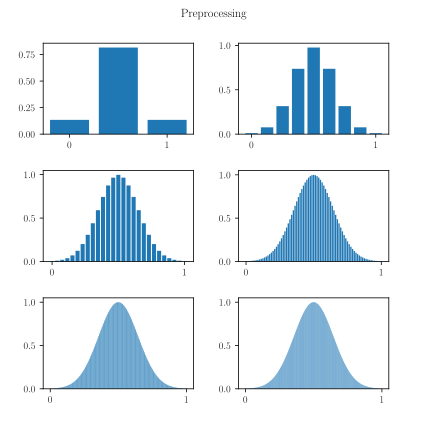

In [5]:

preprocessing_discussion = Discussion(qmap.values[1:])

SVGExporter(
    preprocessing_discussion.single("Preprocessing")
).show()

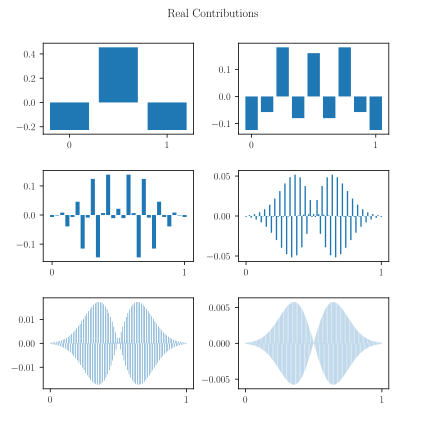

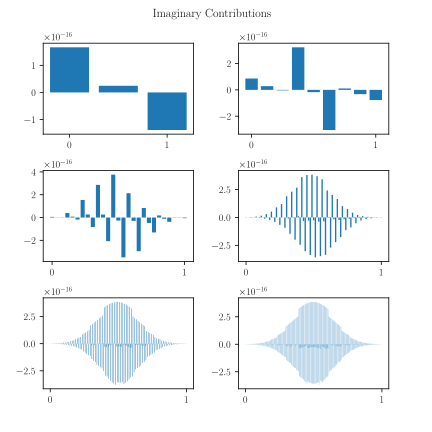

In [6]:
real_discussion = Discussion([np.real(x) for x in qdecomp.contributions])
imag_discussion = Discussion([np.imag(x) for x in qdecomp.contributions])


SVGExporter(
    real_discussion.single("Real Contributions")
).show()

SVGExporter(
    imag_discussion.single("Imaginary Contributions")
).show()

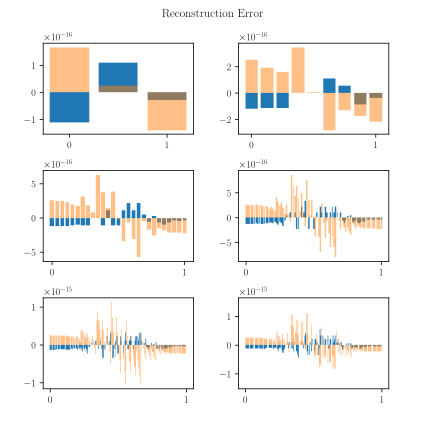

In [7]:
estimate = qrecomp.as_arrays()[1:]
reference = qmap.as_arrays()[1:]
error_discussion = ErrorDiscussion(estimate, reference)

SVGExporter(
    error_discussion.single("Reconstruction Error")
).show()